## Dictionary Attack

This will be a simple example for a dictionary attack.

**Assumptions:**
- The target API has no rate limits.

**Goal:**

We want to find an input that maximizes the models confidence for the class `TARGET_EMOTION`. To do this, we load 28.7k grayscale images of human facial expressions from [FER2013](https://huggingface.co/datasets/SmolVEncoder/fer2013), query the target model with each one, and identify the image that receives the highest `TARGET_EMOTION` score.

In [11]:
import io
import base64
import json
import requests
import numpy as np

from datasets import load_dataset
from matplotlib import pyplot as plt
from tqdm import tqdm

In [ ]:
SEED = 42

# Define target inference server URL
TARGET_SERVER_URL = "http://localhost:8000"
TARGET_EMOTION = "happiness"
MAX_REQUESTS = 50

### 2. Load & Preprocess dataset

In [13]:
df = load_dataset("SmolVEncoder/fer2013").shuffle(seed=SEED)
train_data = df["train"]

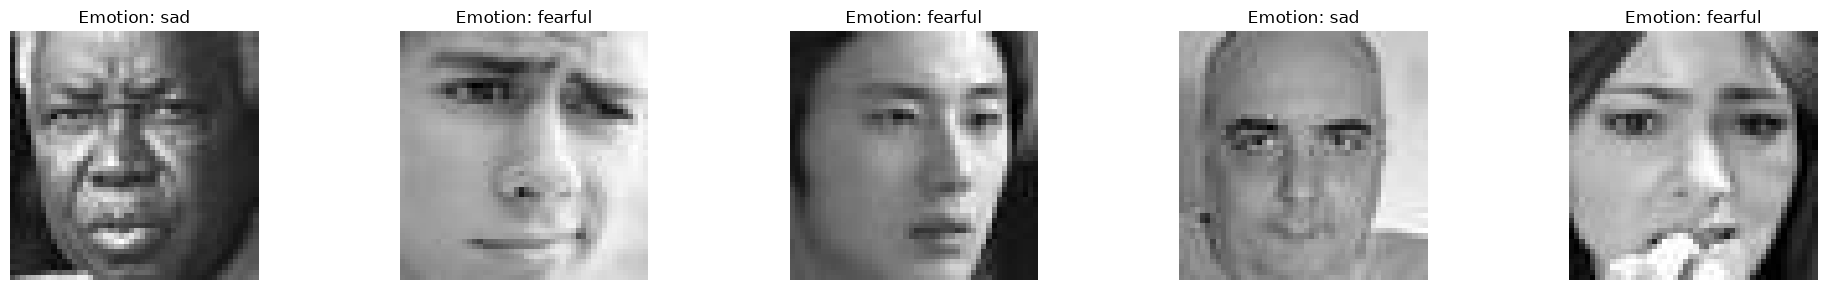

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3))

for i in range(5):
    sample = train_data[i]
    
    image = sample["image"]
    label = sample["label"]
    
    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(f"Emotion: {label}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### 3. Query Dictionary

In [15]:
def request_image(image):
    buffered = io.BytesIO()
    image.save(buffered, format="PNG")
    img_base64 = base64.b64encode(buffered.getvalue()).decode("utf-8")
    
    resp = requests.post(
        TARGET_SERVER_URL + "/predict", 
        headers={"Content-Type": "application/json"}, 
        json={"image": img_base64, "classes": []}
    )
    
    if resp.status_code != 200:
        print(f"Error: {resp.status_code}\n{resp.text}")
    else:
        score = resp.json()["emotions"][TARGET_EMOTION]
        return score


scores = []
for idx in tqdm(range(MAX_REQUESTS)):
    sample = train_data[idx]
    image = sample["image"]
    
    score = request_image(image)
    scores.append(score)

100%|██████████| 50/50 [01:45<00:00,  2.11s/it]


Index with max score: 7, Max score: 1.0


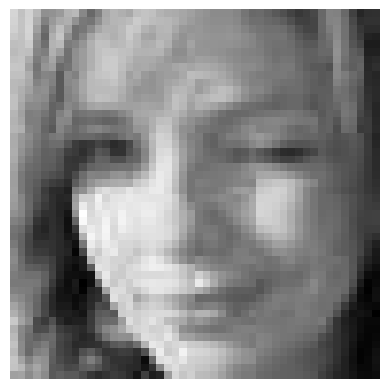

In [16]:
best_idx = np.argmax(scores)

print(f"Index with max score: {best_idx}, Max score: {scores[best_idx]}")

plt.imshow(train_data[best_idx]["image"], cmap="gray")
plt.axis("off")
plt.show()